# Figure 1: SMILES versus CCD input

a) Success rate for SMILES and CCD input per model and target, with the paired Wilcoxon p-value (Benjamini-Hochberg adjusted across the eight comparisons).
b) The same comparison seed by seed.

Success = best of 5 samples within 2 Å; a structure's score is the fraction of its 5 seeds that succeed; the bars are the mean over structures (49 PXR, 85 CYP3A4).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))   # run from notebooks/
import common as C

## Data: the common structure set
Structures that every model and input produced poses for on all five seeds.

In [2]:
B = C.load_poses()
n = B.groupby("target").structure.nunique().to_dict()
print(n)
assert n == {"pxr": 49, "cyp3a4": 85}

{'cyp3a4': 85, 'pxr': 49}


## The table behind panel a
Raw and Benjamini-Hochberg adjusted p-values (paired two-sided Wilcoxon, one pair per structure).

In [3]:
rows = []
for t in ("pxr", "cyp3a4"):
    for m in C.MODELS:
        rows.append(dict(target=t, model=m, **C.pair_stats(C.wide(B, m, t))))
T = pd.DataFrame(rows)
T["p_adj"] = C.bh(T.p)
T.round(4)

,target,model,n,smiles,ccd,p,p_adj
0,pxr,boltz2,49,40.8163,62.8571,0.0008,0.0022
1,pxr,af3,49,42.0408,43.2653,0.7759,0.7759
2,pxr,of3,49,33.0612,42.0408,0.0425,0.0567
3,pxr,obv0,49,29.7959,38.3673,0.0128,0.0205
4,cyp3a4,boltz2,85,42.1176,65.1765,0.0000,0.0000
5,cyp3a4,af3,85,44.7059,58.5882,0.0038,0.0076
6,cyp3a4,of3,85,38.5882,42.5882,0.1140,0.1303
7,cyp3a4,obv0,85,31.2941,43.0588,0.0004,0.0017


## Figure

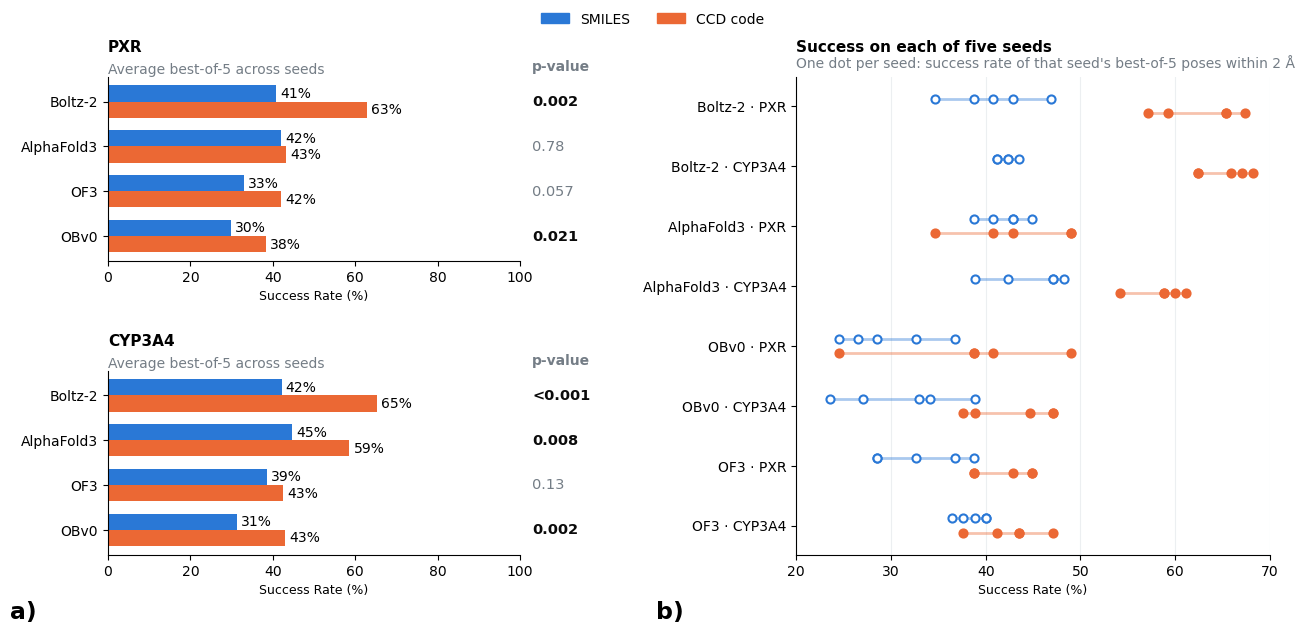

In [4]:
SHIFT_A = 0.055   # nudge the two bar panels left, toward the a) label
PANEL = dict(fontsize=17, fontweight="bold", va="top", ha="left")


def p_fmt(p):
    return "<0.001" if p < 0.001 else (f"{p:.3f}" if p < 0.1 else f"{p:.2f}")


fig = plt.figure(figsize=(14, 6.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.15], hspace=0.6, wspace=0.45)
ax_pxr = fig.add_subplot(gs[0, 0])
ax_cyp = fig.add_subplot(gs[1, 0], sharex=ax_pxr)
ax_seed = fig.add_subplot(gs[:, 1])

# panel a: bars + adjusted p-values
for ax, t, title in ((ax_pxr, "pxr", "PXR"), (ax_cyp, "cyp3a4", "CYP3A4")):
    sub = T[T.target == t]
    C.grouped_bars(ax, [(C.LABEL[r.model], r.smiles, r.ccd) for r in sub.itertuples()], title, "Average best-of-5 across seeds", xlabel="Success Rate (%)")
    ax.text(1.03, 1.02, "p-value", transform=ax.transAxes, fontsize=10, color=C.GREY, fontweight="bold", va="bottom")
    for i, r in enumerate(sub.itertuples()):
        sig = r.p_adj < 0.05
        ax.text(1.03, i, p_fmt(r.p_adj), transform=ax.get_yaxis_transform(), fontsize=10.5, va="center",
                color=C.INK if sig else C.GREY, fontweight="bold" if sig else "normal")
    pos = ax.get_position()
    ax.set_position([pos.x0 - SHIFT_A, pos.y0, pos.width, pos.height])

# panel b: one dot per seed
order = [("boltz2", "pxr"), ("boltz2", "cyp3a4"), ("af3", "pxr"), ("af3", "cyp3a4"),
         ("obv0", "pxr"), ("obv0", "cyp3a4"), ("of3", "pxr"), ("of3", "cyp3a4")]
for i, (m, t) in enumerate(order):
    x = C.wide(B, m, t)
    for k, (inp, col, hollow) in enumerate((("smiles", C.SMILES, True), ("ccd", C.CCD, False))):
        vals = [100 * x[inp][s].mean() for s in sorted(x[inp].columns)]
        yy = i + (k - 0.5) * 0.24
        ax_seed.plot([min(vals), max(vals)], [yy, yy], color=col, alpha=0.4, lw=2, zorder=1)
        ax_seed.scatter(vals, [yy] * len(vals), s=34, facecolors="white" if hollow else col, edgecolors=col, linewidths=1.5, zorder=3)
ax_seed.set_yticks(range(len(order)))
ax_seed.set_yticklabels([f"{C.LABEL[m]} · {'PXR' if t == 'pxr' else 'CYP3A4'}" for m, t in order], fontsize=10)
ax_seed.set_xlim(20, 70)
ax_seed.invert_yaxis()
ax_seed.set_xlabel("Success Rate (%)", fontsize=9)
ax_seed.set_title("Success on each of five seeds", loc="left", fontsize=11, fontweight="bold", pad=18)
ax_seed.text(0, 1.02, "One dot per seed: success rate of that seed's best-of-5 poses within 2 Å", transform=ax_seed.transAxes, fontsize=10, color=C.GREY)
ax_seed.grid(axis="x", color="#eceff1", lw=0.8)
ax_seed.set_axisbelow(True)
for s in ("top", "right"):
    ax_seed.spines[s].set_visible(False)

# panel letters (bottom corners) and legend
y_lab = ax_cyp.get_position().y0 - 0.075
fig.text(0.0, y_lab, "a)", **PANEL)
fig.text(ax_seed.get_position().x0 - 0.10, y_lab, "b)", **PANEL)
fig.legend([plt.Rectangle((0, 0), 1, 1, color=C.SMILES), plt.Rectangle((0, 0), 1, 1, color=C.CCD)],
           ["SMILES", "CCD code"], loc="upper center", ncol=2, frameon=False, fontsize=10)
fig.savefig(C.FIGS / "fig1_smiles_vs_ccd.png", dpi=300, bbox_inches="tight")
plt.show()